# Compact, validation-guided brain MRI classification

**Selected paper baseline:** Disci et al. (2025), Xception. We keep all earlier results.

**Question:** Can a smaller head and staged fine-tuning improve on normalized MobileNetV2 (macro-F1 **0.8062**) while reducing parameters? Secondary target: within **0.02** of audited Xception (**0.9176**).

**A:** existing Flatten head, up to 20 epochs, best-validation checkpoint. **B:** Global Average Pooling, five frozen-backbone warm-up epochs, then up to fifteen low-rate fine-tuning epochs with frozen BatchNorm statistics. Both start from fresh ImageNet weights.

**Verified Colab outcome:** A reaches **88.71% accuracy / 0.8841 macro-F1**; B reaches **92.68% / 0.9256** with **2,422,468 parameters**. B meets both exploratory targets and is chosen by lower validation loss (epoch 17). The original five-epoch hypothesis remains unsupported. The reused test set makes this exploratory; A versus B evaluates a combined method, not individual component effects. These are established techniques, not a new algorithm.

**Colab:** choose **T4 GPU**, Python **3.11/3.12** runtime (previously used: **2026.07**). Upload **brain_mri_training_source.zip** in the Files sidebar. Run all cells and download the results ZIP before disconnecting.

[Keras transfer-learning guidance](https://keras.io/guides/transfer_learning/)

**Presentation mode:** training is disabled by default. Upload the full results ZIP to restore weights, or the source ZIP to review compact evidence. Set `RUN_TRAINING=True` only for a deliberate new run.

In [1]:
import os
import subprocess
import sys
from pathlib import Path
from zipfile import ZipFile

IN_COLAB = Path("/content").exists() and (
    "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
)
if IN_COLAB:
    if sys.version_info[:2] not in [(3, 11), (3, 12)]:
        raise RuntimeError("Select a Python 3.11/3.12 runtime compatible with TensorFlow 2.18.1, such as 2026.07, and reconnect.")
    ROOT = Path("/content/brain_mri_training_extension")
    bundle = next((Path("/content") / name for name in ["brain_mri_training_results.zip", "brain_mri_training_source.zip"] if (Path("/content") / name).exists()), Path("/content/brain_mri_training_source.zip"))
    if not (ROOT / "configs/training_proposed.yaml").exists():
        if not bundle.exists():
            raise FileNotFoundError("Upload brain_mri_training_source.zip in the Files sidebar.")
        with ZipFile(bundle) as archive:
            for entry in archive.infolist():
                if not (ROOT / entry.filename).resolve().is_relative_to(ROOT.resolve()):
                    raise ValueError("Unsafe archive path")
            archive.extractall(ROOT)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")])
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "configs/training_proposed.yaml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
for key, folder in [("KERAS_HOME", "keras"), ("MPLCONFIGDIR", "matplotlib"), ("XDG_CACHE_HOME", "")]:
    os.environ.setdefault(key, str(ROOT / ".cache" / folder))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
print("Project:", ROOT)

Project: /Users/manuchaudhary/ComputerVision_Prj


## 1. Fixed settings and earlier results

Audited dataset version 1: **4,518 train / 798 validation / 1,311 test**. Training split fingerprint must match the earlier run. Crop, 128px input, normalization, augmentation, seed and batch size stay fixed. Test data never enters the checkpoint callback.

`RUN_TRAINING=False` reviews completed results without training. Set it to True only for a new run. Interrupted experiments restart from ImageNet; `--resume` only skips verified completed runs. Allow approximately **20–40 minutes** for setup, audit, training and evaluation; this is an estimate.

In [2]:
import pandas as pd
from IPython.display import Image, display

from src.reproduction.training_comparison import comparison_table, extension_config

RUN_TRAINING = False  # Completed experiments: keep False for the presentation.
OUTPUT_ROOT = ROOT / "outputs/training_extension"
DATA_DIR = ROOT / "data/training_extension"  # Fresh directory; raw images are not in the source ZIP.
# To reuse a complete dataset already in Colab, set DATA_DIR to its parent of Training/Testing.
if RUN_TRAINING:
    import tensorflow as tf
    print("Devices:", tf.config.list_physical_devices())
    if IN_COLAB:
        assert tf.config.list_physical_devices("GPU"), "Select T4 GPU before training."
for experiment in ["control", "proposed"]:
    print(experiment)
    display(pd.Series(extension_config(experiment)))
display(comparison_table(OUTPUT_ROOT).drop(columns="run_dir"))

control


dataset                    masoudnickparvar/brain-tumor-mri-dataset
dataset_version                                                   1
data_dir                                    data/training_extension
output_dir                       outputs/training_extension/control
seed                                                             42
protocol                                            leakage_audited
class_names               [glioma, meningioma, no_tumor, pituitary]
models                                                [MobileNetV2]
image_size                                                      128
batch_size                                                       20
epochs                                                           20
learning_rate                                                0.0001
blur_kernel                                                       5
threshold                                                        45
trainable_backbone                              

proposed


dataset                    masoudnickparvar/brain-tumor-mri-dataset
dataset_version                                                   1
data_dir                                    data/training_extension
output_dir                      outputs/training_extension/proposed
seed                                                             42
protocol                                            leakage_audited
class_names               [glioma, meningioma, no_tumor, pituitary]
models                                                [MobileNetV2]
image_size                                                      128
batch_size                                                       20
epochs                                                           20
learning_rate                                                0.0001
blur_kernel                                                       5
threshold                                                        45
trainable_backbone                              

,experiment,status,accuracy,macro_f1,pituitary_recall,total_parameters,epochs_completed,selected_epoch,best_val_loss,training_seconds,median_inference_ms,environment_matches_normalized_run,macro_f1_gain_over_normalized,xception_macro_f1_gap,parameter_reduction_vs_xception_pct,improves_normalized_with_fewer_parameters,within_xception_margin_with_fewer_parameters
0,Xception reference,measured,0.917620,0.917584,0.993333,25056428,5,5,NaN,239.164533,10.020744,False,0.111384,0.000000,0.000000,None,None
1,Normalized MobileNetV2 (5 epochs),measured,0.819222,0.806200,0.616667,4880068,5,5,NaN,168.552716,5.405546,True,0.000000,0.111384,80.523688,None,None
2,control,measured,0.887109,0.884134,0.800000,4880068,19,15,0.261732,643.069806,5.285838,True,0.077935,0.033450,80.523688,False,False
3,proposed,measured,0.926773,0.925609,0.976667,2422468,20,17,0.093676,382.311291,5.192335,True,0.119409,-0.008025,90.331950,True,True


## 2. Experiment A: longer-training control

Same Flatten architecture and Adam rate **1e-4** as the normalized model. Maximum **20 epochs**. Stop after four consecutive epochs without lower validation loss; export the checkpoint with the lowest validation loss. This changes the training budget and checkpoint policy together.

In [3]:
if RUN_TRAINING:
    subprocess.check_call([
        sys.executable, "scripts/training_extension.py", "train",
        "--experiment", "control", "--data-dir", str(DATA_DIR), "--resume",
    ])
else:
    print("A: training disabled; show only verified stored evidence.")

A: training disabled; show only verified stored evidence.


## 3. Experiment B: compact two-stage adaptation

Replace Flatten with **Global Average Pooling**; keep the Dense(128), dropout and four-class output. Train the head for **5 epochs at 1e-4** with the backbone frozen. Then fine-tune non-BatchNorm backbone layers for up to **15 epochs at 1e-5**. BatchNorm statistics remain frozen. The early-stopping counter resets for fine-tuning. Select the minimum validation loss across **both stages**, even if it occurs in warm-up.

In [4]:
if RUN_TRAINING:
    subprocess.check_call([
        sys.executable, "scripts/training_extension.py", "train",
        "--experiment", "proposed", "--data-dir", str(DATA_DIR), "--resume",
    ])
else:
    print("B: training disabled; no new accuracy is assumed.")

B: training disabled; no new accuracy is assumed.


## 4. Verified comparison and error analysis

All displayed test metrics are recomputed from saved ordered predictions. Compare macro-F1, **pituitary recall**, parameters and time. Historical Xception uses a different training policy and possibly a different environment; this is a reference target, not an equal-budget architecture comparison.

Choose the demo model between A and B using **lowest validation loss**, regardless of test ranking. A negative result remains a valid outcome; do not tune again on the test set.

Demo model chosen by validation loss: proposed


,experiment,status,accuracy,macro_f1,pituitary_recall,total_parameters,epochs_completed,selected_epoch,best_val_loss,training_seconds,median_inference_ms,environment_matches_normalized_run,macro_f1_gain_over_normalized,xception_macro_f1_gap,parameter_reduction_vs_xception_pct,improves_normalized_with_fewer_parameters,within_xception_margin_with_fewer_parameters
0,Xception reference,measured,0.917620,0.917584,0.993333,25056428,5,5,NaN,239.164533,10.020744,False,0.111384,0.000000,0.000000,None,None
1,Normalized MobileNetV2 (5 epochs),measured,0.819222,0.806200,0.616667,4880068,5,5,NaN,168.552716,5.405546,True,0.000000,0.111384,80.523688,None,None
2,control,measured,0.887109,0.884134,0.800000,4880068,19,15,0.261732,643.069806,5.285838,True,0.077935,0.033450,80.523688,False,False
3,proposed,measured,0.926773,0.925609,0.976667,2422468,20,17,0.093676,382.311291,5.192335,True,0.119409,-0.008025,90.331950,True,True


control — selected epoch 15


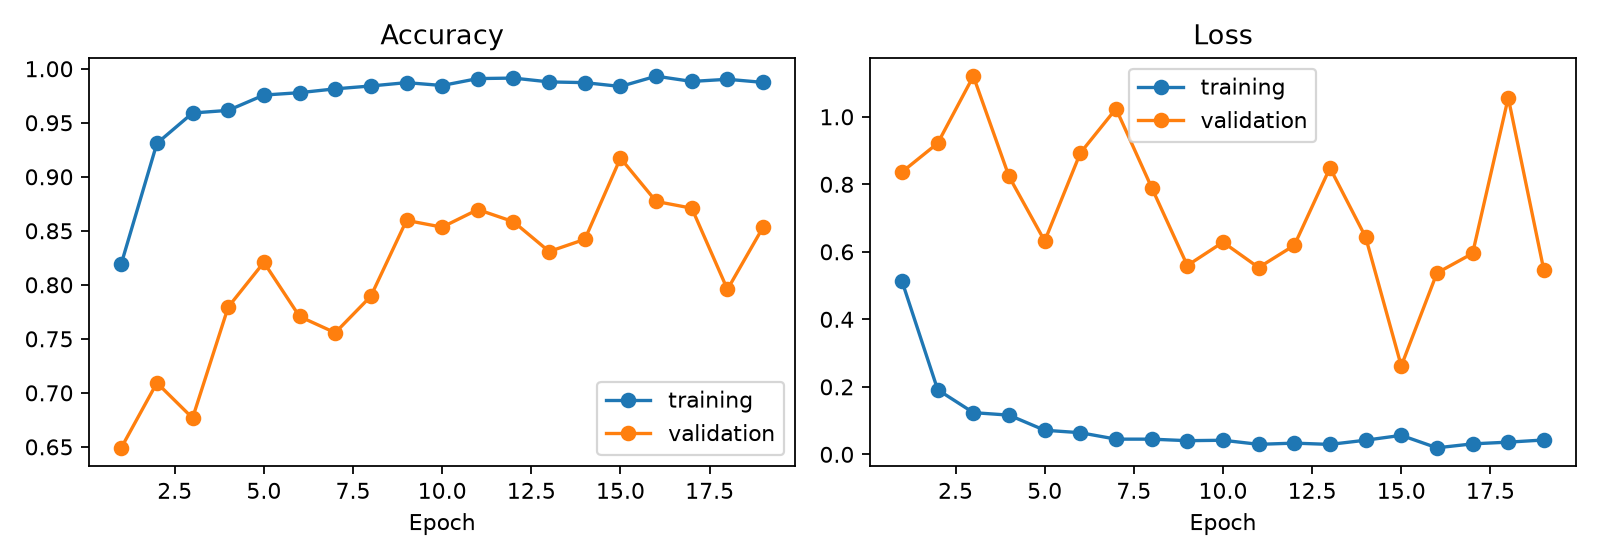

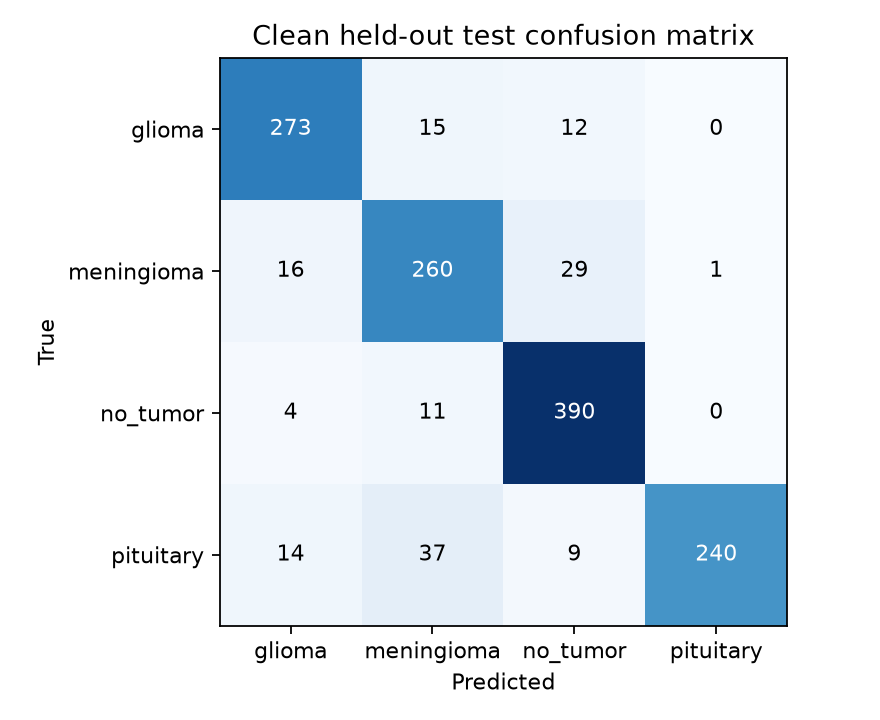

proposed — selected epoch 17


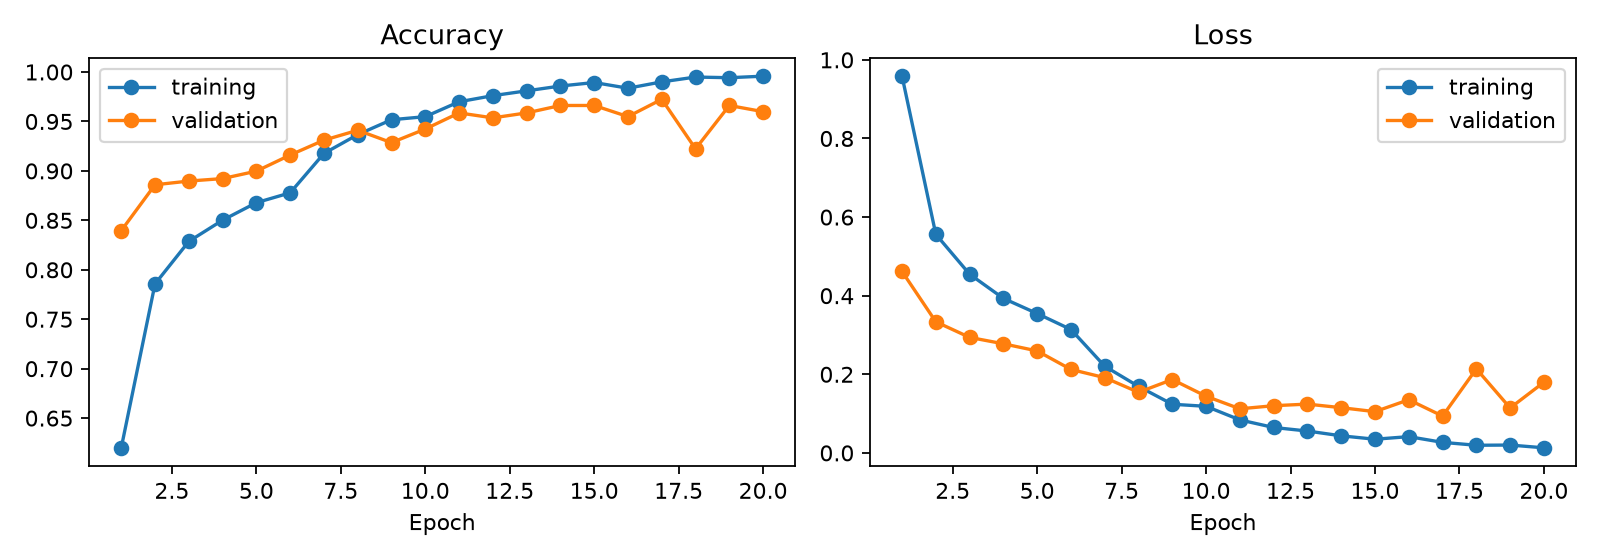

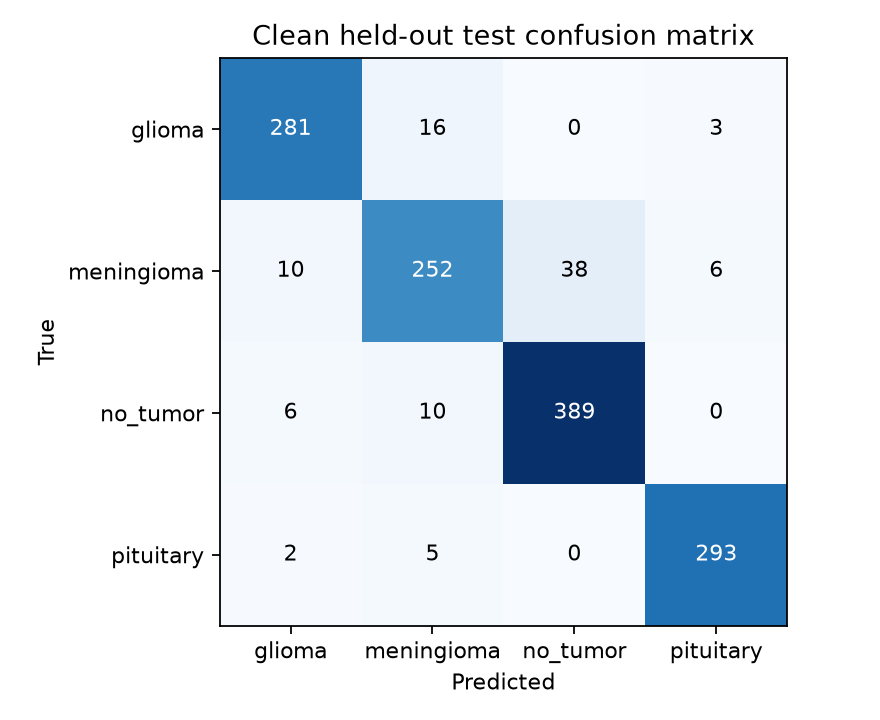

In [5]:
table = comparison_table(OUTPUT_ROOT)
result_dir = ROOT / "results/training_extension"
result_dir.mkdir(parents=True, exist_ok=True)
table.to_csv(result_dir / "comparison.csv", index=False)
new = table[table.experiment.isin(["control", "proposed"]) & (table.status == "measured")]
SELECTED_EXPERIMENT = None
if not new.empty:
    SELECTED_EXPERIMENT = new.sort_values("best_val_loss").iloc[0].experiment
    print("Demo model chosen by validation loss:", SELECTED_EXPERIMENT)
display(table.drop(columns="run_dir"))
for _, row in new.iterrows():
    print(row.experiment, "— selected epoch", int(row.selected_epoch))
    for filename in ["learning_curves.png", "confusion_matrix.png"]:
        display(Image(filename=str(Path(row.run_dir) / filename), width=750))
if new.empty:
    print("New full-data experiments pending. Earlier baseline results remain available.")

## 5. Saved-model prediction

Predict an existing MRI slice using the identical training crop and model-contained normalization. Leave `DEMO_IMAGE` empty to use the first test image; or set it to an uploaded JPG/PNG. This demonstration is not an independent accuracy estimate. Softmax scores are not calibrated diagnostic probabilities.

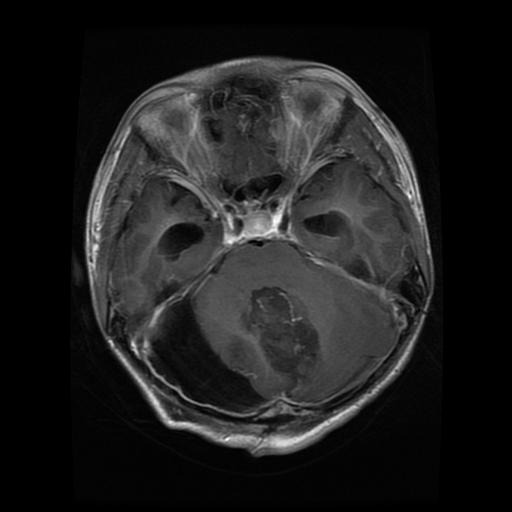

Known label: glioma


Predicted: glioma


glioma        9.999839e-01
meningioma    1.600787e-05
no_tumor      5.906003e-08
pituitary     3.446348e-08
Name: Softmax scores, dtype: float64

Model softmax scores are not calibrated diagnostic probabilities.


In [6]:
from src.reproduction.final_project import predict_image

DEMO_IMAGE = ""  # Example: /content/my_mri.jpg
if SELECTED_EXPERIMENT:
    if not IN_COLAB:
        import tensorflow as tf
        tf.config.set_visible_devices([], "GPU")
    run = OUTPUT_ROOT / SELECTED_EXPERIMENT / "leakage_audited/MobileNetV2"
    if (run / "model.keras").exists():
        test = pd.read_csv(run / "test_manifest.csv")
        image = Path(DEMO_IMAGE) if DEMO_IMAGE else DATA_DIR / test.iloc[0].path
        if not image.exists() and not DEMO_IMAGE:
            image = ROOT / "data/raw" / test.iloc[0].path
        if image.exists():
            display(Image(filename=str(image), width=280))
            if not DEMO_IMAGE:
                print("Known label:", test.iloc[0].class_name)
            prediction = predict_image(run, image)
            print("Predicted:", prediction["predicted_class"])
            display(pd.Series(prediction["scores"], name="Softmax scores"))
            print(prediction["note"])
        else:
            print("Choose an existing image; raw MRI images are excluded from exports.")
    else:
        print("Restore the full results bundle to use the saved checkpoint.")
else:
    print("Complete at least one experiment first.")

## 6. Download evidence and model weights

Download **before disconnecting**. The ZIP contains accepted completed models, configurations, histories, predictions and compact comparison evidence; raw images are excluded. If B is interrupted, run this cell to preserve completed A. Also use **File > Download > Download .ipynb** to retain this notebook's actual executed outputs.

After the run, import the ZIP for verification and update the report/PPT with actual outcomes. Preserve prior negative hypotheses. Limitations: one seed, already examined test set, unresolved near-matches, duplicate test images and missing patient IDs. No patient-independent, clinical or new-algorithm claim.

In [7]:
from scripts.package_training_extension import package_extension

has_model = any(
    (OUTPUT_ROOT / experiment / "leakage_audited/MobileNetV2/model.keras").exists()
    for experiment in ["control", "proposed"]
)
if has_model:
    destination = (Path("/content/brain_mri_training_results.zip") if IN_COLAB
                   else ROOT / "deliverables/brain_mri_training_results.zip")
    archive = package_extension(destination, include_models=True)
    if IN_COLAB:
        from google.colab import files
        files.download(str(archive))
else:
    print("No completed model weights to export yet.")

Exporting completed models: control, proposed


Saved /Users/manuchaudhary/ComputerVision_Prj/deliverables/brain_mri_training_results.zip (85,739,661 bytes)
